# 03 · Survival analysis
**Question:** how many days does an ad stay healthy, by format?

- **Duration** = days from launch until fatigue
- **Event** = 1 if fatigue happened, 0 if not seen (**censored**: paused early or still running at export)

Kaplan-Meier uses censored ads correctly; a simple average would drop them or count them as fatigued, and underestimate ad life.

In [1]:
# cell 1: load
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

ROOT = Path.cwd().parent
FIG = ROOT / "reports" / "figures"
summary = pd.read_csv(ROOT / "data/processed/ad_summary.csv")
summary["event_observed"].value_counts().rename({1: "fatigued", 0: "censored"})

event_observed
fatigued    100
censored     14
Name: count, dtype: int64

In [2]:
# cell 2: one curve for all ads
kmf = KaplanMeierFitter()
kmf.fit(summary["duration_days"], event_observed=summary["event_observed"], label="all ads")
print("Median healthy life, all ads:", kmf.median_survival_time_, "days")

Median healthy life, all ads: 14.0 days


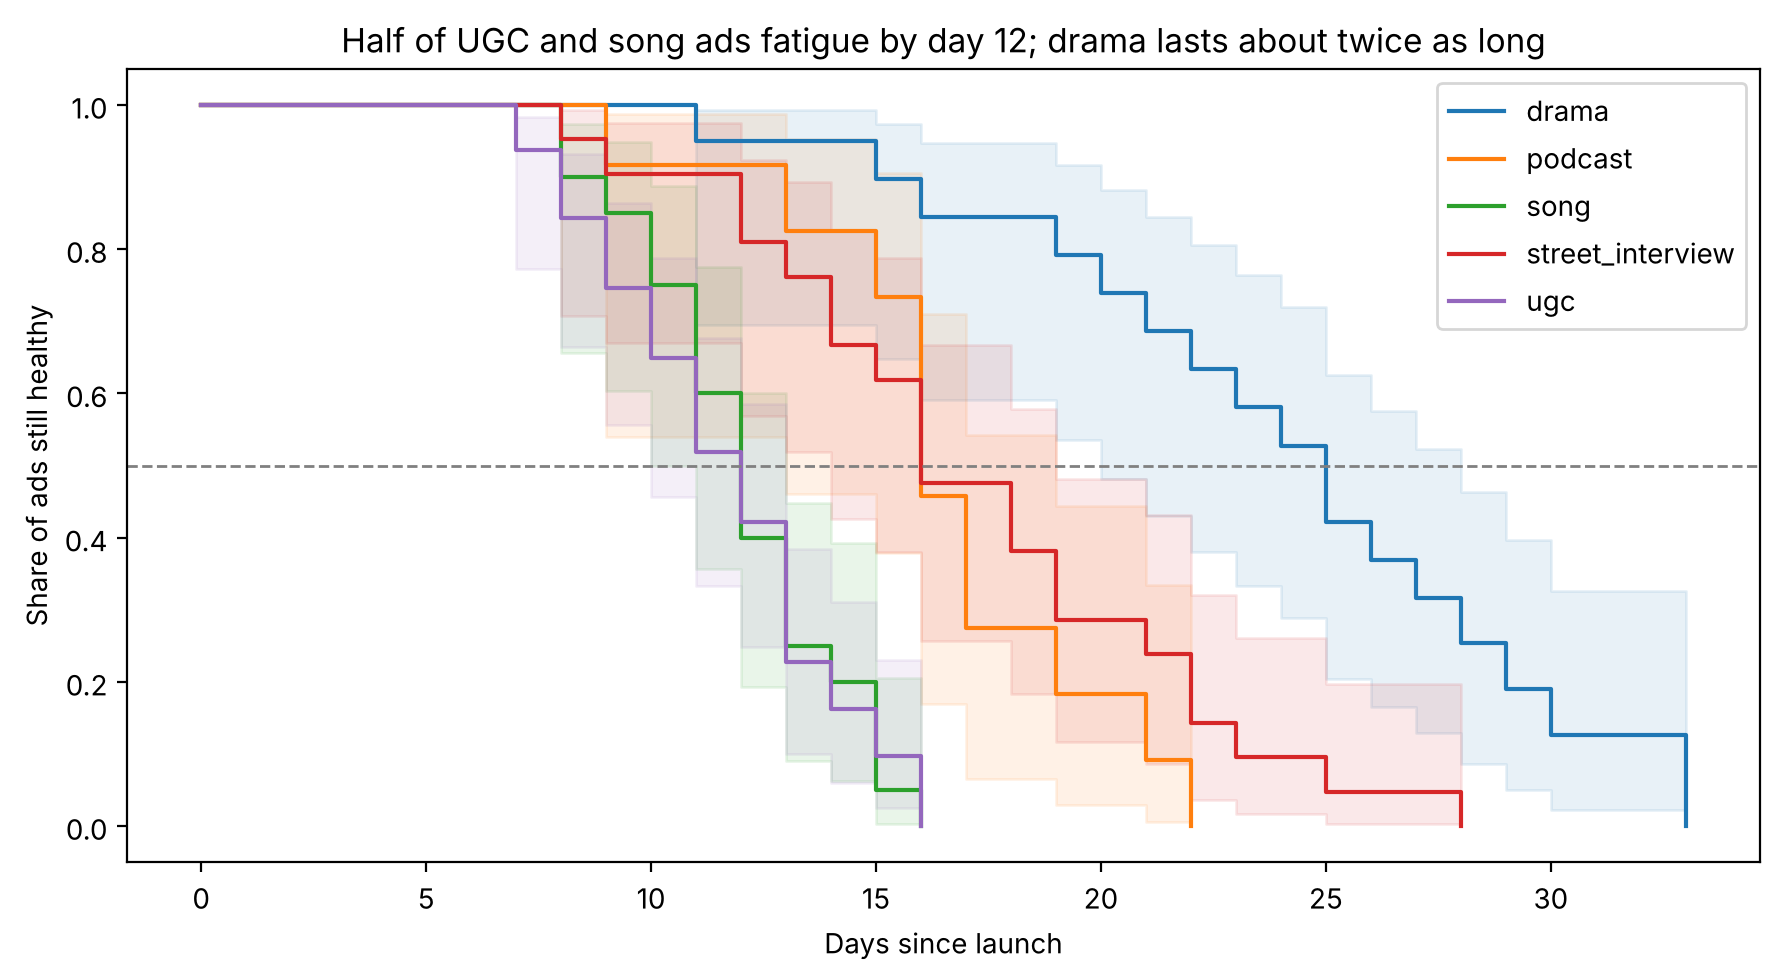

song                12.0
ugc                 12.0
street_interview    16.0
podcast             16.0
drama               25.0
Name: median_healthy_days, dtype: float64

In [3]:
# cell 3: one curve per format
fig, ax = plt.subplots(figsize=(9, 5))
medians = {}
for fmt, part in summary.groupby("format"):
    kmf = KaplanMeierFitter()
    kmf.fit(part["duration_days"], event_observed=part["event_observed"], label=fmt)
    kmf.plot_survival_function(ax=ax, ci_show=True, ci_alpha=0.1)
    medians[fmt] = kmf.median_survival_time_
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Days since launch")
ax.set_ylabel("Share of ads still healthy")
ax.set_title("Half of UGC and song ads fatigue by day 12; drama lasts about twice as long")
plt.tight_layout(); plt.savefig(FIG / "survival_by_format.png", dpi=150); plt.show()
pd.Series(medians, name="median_healthy_days").sort_values()

In [4]:
# cell 4: are the formats really different?
result = multivariate_logrank_test(summary["duration_days"], summary["format"], summary["event_observed"])
print(f"Log-rank test p-value: {result.p_value:.2g}")

Log-rank test p-value: 1.9e-15


**So what:** median healthy life is 14 days overall: **12 days** for UGC and song, 16 for street interview and podcast, and **25 days** for drama. The log-rank test (p ≈ 2 × 10⁻¹⁵) shows the formats really differ.

**Business use:** brief a fresh UGC or song creative roughly every 10 days; drama creatives can run about three weeks.